## Modeling

For the modeling phase of this project, 6 classification algorithms are used.
They are:
- Logistic Regression
- K-Nearest Neighors (KNN)
- Support Vector Machine (SVM)
- Decision Tree
- Random Forest
- Gradient Boosting

### Feature and Target Separation

In [1]:
import pandas as pd

df_clean = pd.read_csv("../data/diabd_clean.csv")
df_clean.head()

,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,0.0,66,110,73,5.88,1.65,70.2,25.75,0,0,0,0,0,0
1,35,0.0,60,125,68,5.71,1.47,42.5,19.58,0,0,0,0,0,0
2,62,0.0,57,127,74,6.85,1.52,47.0,20.24,0,0,0,0,0,0
3,73,1.0,55,193,112,6.28,1.63,57.4,21.72,0,0,0,0,0,0
4,68,0.0,71,150,81,5.71,1.42,36.0,17.79,0,0,0,0,0,0


In [2]:
X = df_clean.drop(columns=['diabetic'])
y = df_clean['diabetic']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5287, 14)
Target shape: (5287,)


### Train-Test Split

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target proportion:", y_train.value_counts(normalize=True).round(3))
print("Testing target proportion:", y_test.value_counts(normalize=True).round(3))

Training features shape: (4229, 14)
Testing features shape: (1058, 14)
Training target proportion: diabetic
0    0.935
1    0.065
Name: proportion, dtype: float64
Testing target proportion: diabetic
0    0.936
1    0.064
Name: proportion, dtype: float64


### Model Selection and Training

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()), 
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ]),

    "Decision Tree": Pipeline([
        ("model", DecisionTreeClassifier(random_state=42))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200, 
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}


Training the models

In [5]:
for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name} model trained successfully.")

Logistic Regression model trained successfully.
KNN model trained successfully.


/Users/emmanuelagyen/Library/CloudStorage/GoogleDrive-obengagyen@gmail.com/My Drive/Everything_Tech/ML/ML_Projects/Diabetes_Risk_Prediction/.venv/lib/python3.13/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM model trained successfully.
Decision Tree model trained successfully.
Random Forest model trained successfully.
Gradient Boosting model trained successfully.


### Model Evaluation

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, y_proba),
        "Average Precision": average_precision_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="Recall",
    ascending=False
).round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Average Precision
3,Decision Tree,0.907,0.297,0.324,0.310,0.636,0.140
5,Gradient Boosting,0.939,0.556,0.221,0.316,0.850,0.412
0,Logistic Regression,0.934,0.455,0.147,0.222,0.821,0.311
1,KNN,0.934,0.450,0.132,0.205,0.681,0.185
2,SVM,0.938,0.571,0.118,0.195,0.711,0.289
4,Random Forest,0.937,0.533,0.118,0.193,0.844,0.317


Visualization of model comparison

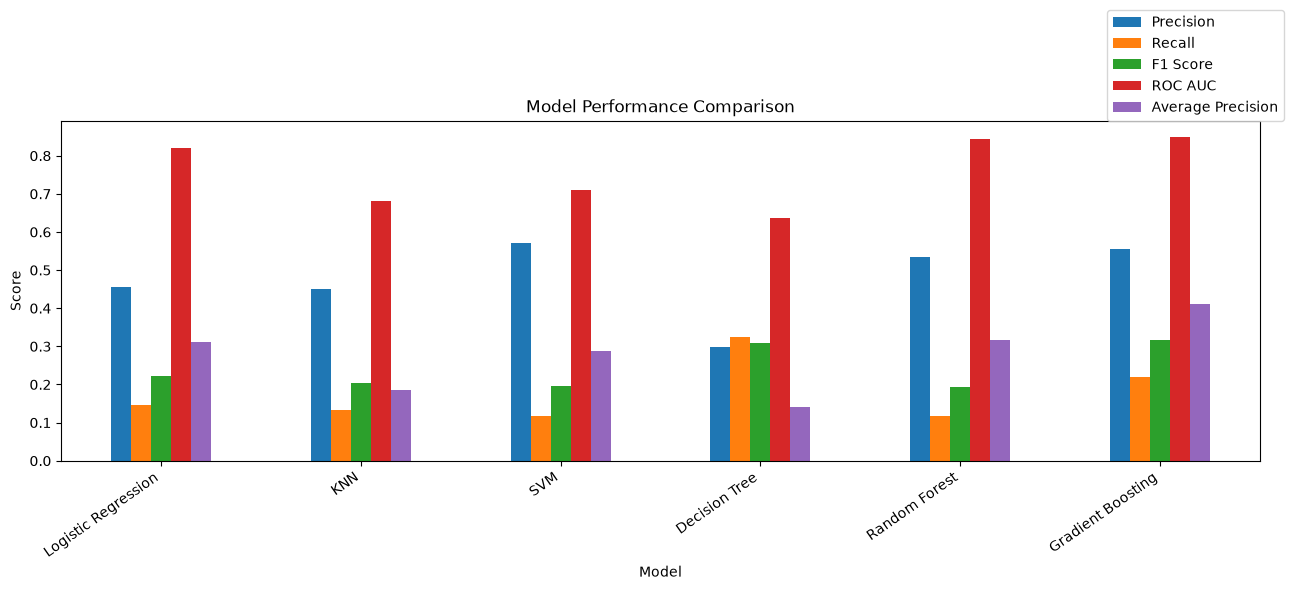

In [17]:
import matplotlib.pyplot as plt

results_df.set_index("Model")[
    ["Precision", "Recall", "F1 Score", "ROC AUC", "Average Precision"]
].plot(
    kind="bar",
    figsize=(13, 6),
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=35, ha="right")
plt.legend(loc="lower right", bbox_to_anchor=(1.02, 1.0), borderaxespad=0)
plt.tight_layout()
plt.show()

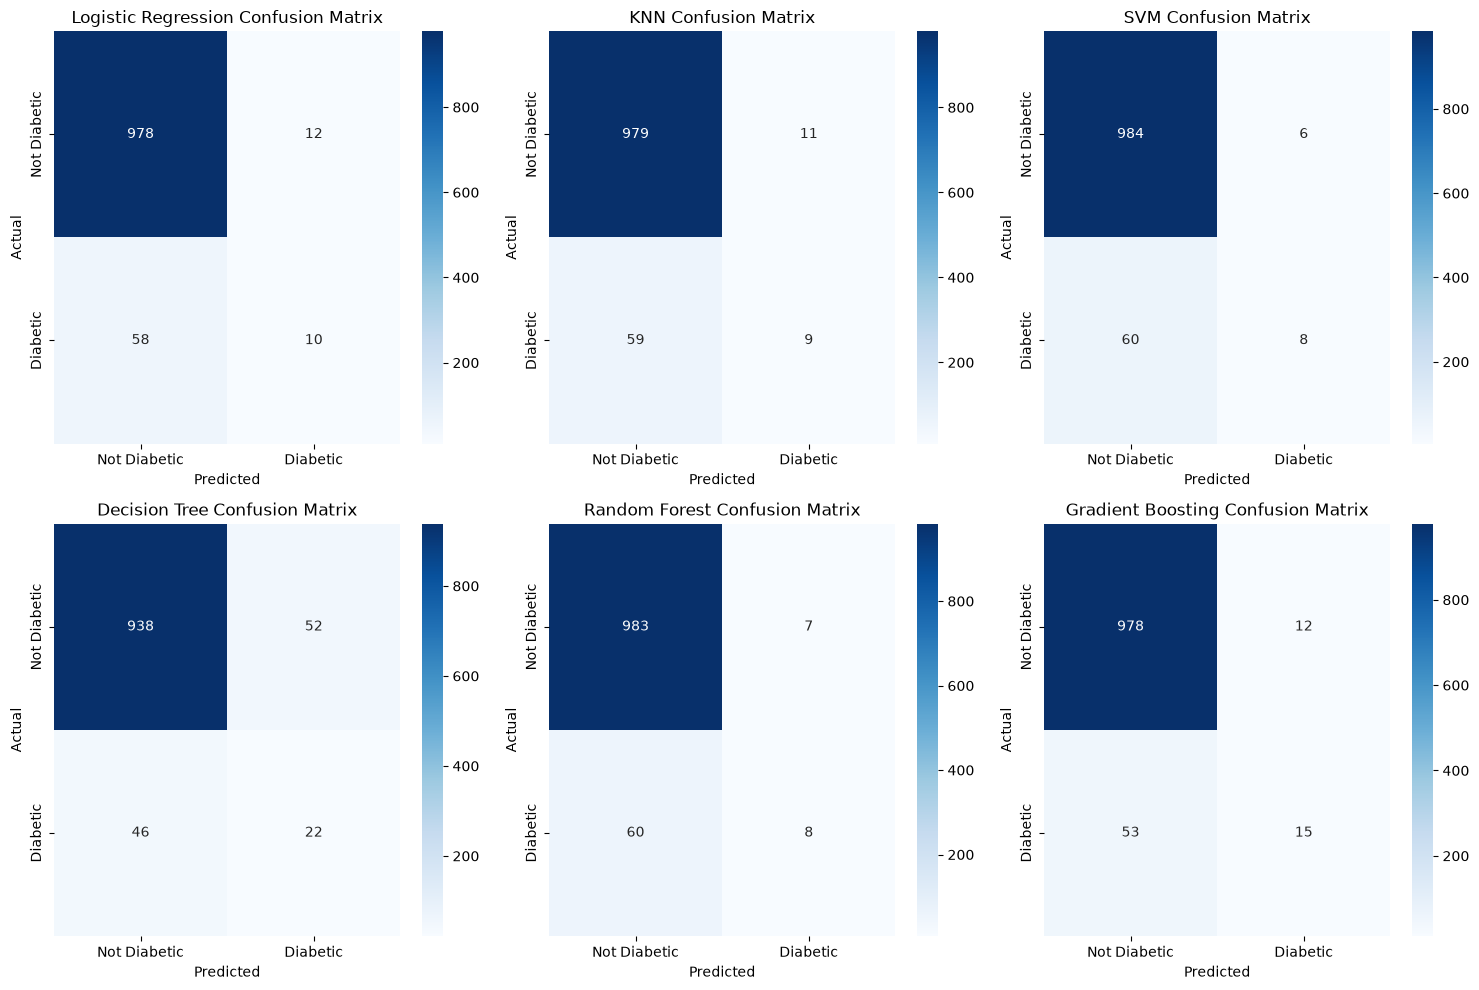

In [18]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

for ax, (name, model) in zip(axes.flatten(), models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm, 
        annot=True, 
        fmt="d", 
        cmap="Blues", 
        xticklabels=["Not Diabetic", "Diabetic"],
        yticklabels=["Not Diabetic", "Diabetic"],
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()